# Tarea 2 · Parte 2: evaluación de modelos y extracción estructurada

**Pregunta:** ¿qué tan bien leen y transcriben los modelos abiertos documentos y entrevistas peruanas, y cuál conviene usar en un entorno real?

| | |
|---|---|
| **Muestra** | 10 documentos (3 impresos, 3 fotos, 4 manuscritos) y 10 clips (una fuente o condición de grabación distinta cada uno), tomados del corpus de la Parte 1 y definidos en `referencias.py` antes de calcular cualquier métrica |
| **Referencias** | transcripción manual de esos 20 archivos (`texto_referencia` en `datos/documentos.csv` y `datos/transcripciones.csv`; respaldo en `datos/referencias.json`), hecha con `referencias.html` sin ver las salidas de los modelos |
| **OCR comparados** | PaddleOCR 3.7.0 por defecto (línea base), PaddleOCR con la configuración de la Parte 1 y Tesseract 5 (`spa`) |
| **ASR comparados** | faster-whisper `small` en CPU (línea base), faster-whisper `large-v3-turbo` en GPU y Meta MMS `mms-1b-all` (`spa`) en GPU |
| **Dónde se corrió** | los modelos nuevos, en Google Colab con `modelos_colab.ipynb` (GPU T4); las salidas están en `datos/evaluacion/` y este notebook solo las lee |
| **LLM** | Gemini (Google), con salida JSON validada contra un esquema; resultados en `datos/extraccion_llm.csv` |

Las configuraciones de todos los modelos se fijaron antes de ver las métricas y no se ajustaron después.

In [1]:
import json, os, re, time, unicodedata
from pathlib import Path
import jiwer
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import Image as Img, display
from referencias import MUESTRA_DOCS, MUESTRA_CLIPS

pd.set_option("display.max_colwidth", 120)
EVAL = Path("datos/evaluacion")
GRAF = Path("graficos"); GRAF.mkdir(exist_ok=True)
documentos = pd.read_csv("datos/documentos.csv", dtype={"texto_referencia": str}).fillna({"texto_referencia": ""})
transcripciones = pd.read_csv("datos/transcripciones.csv", dtype={"texto_referencia": str}).fillna({"texto_referencia": ""})
entorno = json.loads((EVAL / "entorno.json").read_text(encoding="utf-8"))
print("jiwer", jiwer.__version__ if hasattr(jiwer, "__version__") else "", "| entorno de Colab:", entorno)

jiwer  | entorno de Colab: {'paddleocr': '3.7.0', 'paddlepaddle': '3.2.2', 'tesseract': 'tesseract 5.3.4', 'faster_whisper': '1.2.1', 'transformers': '5.20.2', 'torch': '2.11.0+cu130', 'gpu': 'Tesla T4', 'cpu_nucleos': 2, 'python': '3.13.16'}


## 1. Muestra de evaluación y referencias manuales

Los 10 documentos cubren los tres tipos y, dentro de cada tipo, piezas distintas (dos constituciones y una gaceta; placas de tres ciudades; dos cartas de escritores, la portada de un libro parroquial y una carta familiar de 2010). Los 10 clips vienen cada uno de una fuente o condición distinta: calle con tráfico, marcha, fiesta con música, acento andino, entrevista con 3 o 4 voces y testimonio grabado con buena calidad. Se eligieron por esa variedad y por su duración (entre 39 s y 2,6 min, unos 15 min en total), para que la transcripción manual fuera posible con cuidado.

**Cómo se hicieron las referencias.** A mano, mirando la imagen o escuchando el audio en `referencias.html`, con el cuadro de texto vacío (sin partir de la salida de ningún modelo). Criterios:
- copia literal, sin corregir la ortografía del original;
- `[?]` en lo ilegible o inaudible;
- `[PERSONA]` en los nombres de personas privadas, igual que la seudonimización de la Parte 1.

Lo que va entre corchetes no se cuenta en las métricas.

**Un cambio en la muestra.** Al principio el cuarto manuscrito era la carta de Miguel Grau de 1879 (`doc_r05`), pero al transcribirla no se pudo leer casi nada: cursiva muy apretada y foto tomada a través de un vidrio. Sin una referencia confiable no se puede medir nada, así que se cambió por `doc_022`, una carta manuscrita de 2010. El cambio se hizo por lo que pudo leer la persona y antes de calcular cualquier métrica, no por los resultados de los modelos. La carta de Grau sigue en el corpus y en la extracción con el LLM.

In [2]:
muestra_doc = documentos[documentos.id.isin(MUESTRA_DOCS)].assign(descripcion=lambda d: d.id.map(MUESTRA_DOCS))
muestra_aud = transcripciones[transcripciones.id.isin(MUESTRA_CLIPS)].assign(descripcion=lambda d: d.id.map(MUESTRA_CLIPS))
con_ref_doc = (muestra_doc.texto_referencia.str.strip() != "").sum()
con_ref_aud = (muestra_aud.texto_referencia.str.strip() != "").sum()
print(f"Referencias manuales: {con_ref_doc}/10 documentos y {con_ref_aud}/10 clips · "
      f"{muestra_aud.duracion_seg.sum() / 60:.1f} min de audio en la muestra")
pd.concat([muestra_doc[["id", "tipo", "descripcion"]],
           muestra_aud.assign(tipo="audio")[["id", "tipo", "descripcion"]]], ignore_index=True)

Referencias manuales: 10/10 documentos y 10/10 clips · 15.2 min de audio en la muestra


,id,tipo,descripcion
0,doc_002,impreso,"impreso · Constitución de 1828, portada"
1,doc_003,impreso,"impreso · Constitución de 1856, encabezado"
2,doc_004,impreso,"impreso · Gazeta del Gobierno de Lima, 1810 (tipografía antigua)"
3,doc_009,foto,"foto · placa del Teatro Colón, Lima"
4,doc_013,foto,"foto · placa del terremoto de 2001, Arequipa"
5,doc_016,foto,"foto · placa de la Casa Amorós, Trujillo"
6,doc_018,manuscrito,"manuscrito · carta de Bachmann a Palma, 1912 (cursiva)"
7,doc_021,manuscrito,"manuscrito · carta de Vallejo a Eguren, 1917"
8,doc_022,manuscrito,"manuscrito · carta a un hermano, 2010 (letra moderna)"
9,doc_025,manuscrito,"manuscrito · Libro de Bautismos de Lampa, 1871 (portada)"


## 2. Normalización y métricas

Referencia y salida de cada modelo pasan por **la misma** función `normalizar`:
1. Se quitan las marcas entre corchetes: `[HABLANTE_1]`, `[PERSONA_2]`, `[?]`. No son palabras habladas ni texto del documento.
2. Minúsculas y forma Unicode NFC (la «é» compuesta y la precompuesta cuentan igual).
3. Se quita la puntuación (Whisper la pone, MMS no, y en los documentos la de la referencia depende de cómo se lea la imagen) y se juntan los espacios y saltos de línea en un solo espacio.
4. **Las tildes se mantienen**: confundir «está» con «esta» es un error real de lectura.

Métricas, con `jiwer`:
- **CER** (documentos) = (sustituciones + borrados + inserciones de caracteres) / caracteres de la referencia.
- **WER** (audio) = lo mismo, contando palabras.
- **RTF** (factor de tiempo real) = tiempo de proceso / duración del audio. Menor que 1 significa más rápido que el audio.

Se reporta el promedio por archivo y la tasa global (errores totales / longitud total de referencias). La global pesa más los archivos largos; las dos se muestran para que un clip corto no domine el resultado.

In [3]:
def normalizar(texto):
    texto = re.sub(r"\[[^\]]*\]", " ", str(texto or ""))
    texto = unicodedata.normalize("NFC", texto).lower()
    texto = re.sub(r"[^\w\s]|_", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

def metricas(refs, hips, unidad):
    """Tasa por archivo y global (CER si unidad='c', WER si unidad='w')."""
    filas = []
    for r, h in zip(refs, hips):
        r, h = normalizar(r), normalizar(h)
        if unidad == "c":
            o = jiwer.process_characters(r, h)
            n = len(r)
        else:
            o = jiwer.process_words(r, h)
            n = len(r.split())
        errores = o.substitutions + o.deletions + o.insertions
        filas.append({"errores": errores, "n_ref": n, "tasa": errores / n if n else np.nan})
    return pd.DataFrame(filas, columns=["errores", "n_ref", "tasa"])

ejemplo = "[HABLANTE_1] Sí, ESTÁ bien... [PERSONA_1] vino ¿no?"
print(repr(normalizar(ejemplo)))
print(metricas(["está bien vino no"], ["esta bien vino"], "w").to_dict("records"))

'sí está bien vino no'
[{'errores': 2, 'n_ref': 4, 'tasa': 0.5}]


## 3. Salidas de los modelos sobre la muestra

Cada modelo se corrió una sola vez con su configuración fija:
- **PaddleOCR por defecto**: `PaddleOCR(lang="es")` sin cambiar nada; activa por su cuenta la corrección de orientación del documento, el enderezado de páginas curvas y la orientación de cada línea, con el detector y el reconocedor PP-OCRv6 medium (`PP-OCRv6_medium_det` y `PP-OCRv6_medium_rec`).
- **PaddleOCR Parte 1**: detector liviano `PP-OCRv5_mobile_det`, imagen a 1280 px como máximo y sin esos tres modelos extra (ver `01_extraccion.ipynb`). Sale de los JSON de la Parte 1.
- **Tesseract 5**: `lang="spa"`, `--psm 3` (segmentación automática de la página), sin preprocesar la imagen.
- **faster-whisper small** (CPU, int8) y **large-v3-turbo** (GPU, float16): `language="es"`, `beam_size=5`, `vad_filter=True`.
- **MMS** `mms-1b-all` con el adaptador de español, en ventanas de 30 s con 5 s de solapamiento (es un modelo CTC: no tiene el límite de 30 s de Whisper, pero sí de memoria).

En la muestra de audio se usa el texto **sin diarización** de cada modelo: la WER mide solo las palabras.

In [4]:
def leer(nombre):
    return json.loads((EVAL / f"{nombre}.json").read_text(encoding="utf-8"))

# texto de la Parte 1 ya seudonimizado, igual que las salidas de Colab y las referencias
ocr_p1 = dict(zip(documentos.id, documentos.texto_ocr))
OCR = {
    "PaddleOCR por defecto (base)": {i: v["texto"] for i, v in leer("ocr_paddle_base").items()},
    "PaddleOCR config. Parte 1": ocr_p1,
    "Tesseract 5 (spa)": {i: v["texto"] for i, v in leer("ocr_tesseract").items()},
}
ASR = {
    "faster-whisper small · CPU (base)": leer("asr_whisper_small_cpu"),
    "faster-whisper large-v3-turbo · GPU": leer("asr_whisper_turbo_gpu"),
    "MMS mms-1b-all spa · GPU": leer("asr_mms_gpu"),
}
for k, v in {**OCR, **ASR}.items():
    print(f"{k}: {len(v)} archivos")

PaddleOCR por defecto (base): 10 archivos
PaddleOCR config. Parte 1: 25 archivos
Tesseract 5 (spa): 10 archivos
faster-whisper small · CPU (base): 10 archivos
faster-whisper large-v3-turbo · GPU: 10 archivos
MMS mms-1b-all spa · GPU: 10 archivos


## 4. Línea base y comparación de modelos

In [5]:
ref_doc = muestra_doc.set_index("id").texto_referencia
ref_aud = muestra_aud.set_index("id").texto_referencia
listos_doc = [i for i in MUESTRA_DOCS if ref_doc[i].strip()]
listos_aud = [i for i in MUESTRA_CLIPS if ref_aud[i].strip()]

por_doc = pd.concat([
    metricas(ref_doc[listos_doc], [OCR[m].get(i, "") for i in listos_doc], "c")
    .assign(modelo=m, id=listos_doc, tipo=muestra_doc.set_index("id").tipo[listos_doc].values)
    for m in OCR], ignore_index=True)
por_clip = pd.concat([
    metricas(ref_aud[listos_aud], [ASR[m][i]["texto"] for i in listos_aud], "w")
    .assign(modelo=m, id=listos_aud, rtf=[ASR[m][i]["rtf"] for i in listos_aud],
            segundos=[ASR[m][i]["segundos"] for i in listos_aud])
    for m in ASR], ignore_index=True)

def resumen(df, nombre):
    g = df.groupby("modelo", sort=False)
    out = pd.DataFrame({f"{nombre} promedio": g.tasa.mean(), f"{nombre} global": g.errores.sum() / g.n_ref.sum()})
    if "rtf" in df:
        out["RTF medio"] = g.rtf.mean()
    return out.round(3)

print(f"Documentos con referencia: {len(listos_doc)}/10 · clips con referencia: {len(listos_aud)}/10")
tabla_ocr, tabla_asr = resumen(por_doc, "CER"), resumen(por_clip, "WER")
display(tabla_ocr); display(tabla_asr)

Documentos con referencia: 10/10 · clips con referencia: 10/10


,CER promedio,CER global
modelo,,
PaddleOCR por defecto (base),0.291,0.306
PaddleOCR config. Parte 1,0.282,0.369
Tesseract 5 (spa),0.697,0.708


,WER promedio,WER global,RTF medio
modelo,,,
faster-whisper small · CPU (base),0.335,0.337,0.415
faster-whisper large-v3-turbo · GPU,0.303,0.307,0.033
MMS mms-1b-all spa · GPU,0.447,0.457,0.013


**Línea base.** La primera fila de cada tabla es la configuración base que pide la consigna: PaddleOCR sin personalización y faster-whisper `small` en CPU. Estos son los valores de referencia contra los que se comparan los demás.

El RTF de `small` es el de la CPU de Colab (2 núcleos). En la laptop, el mismo modelo con los 23 clips de la Parte 1 tuvo el RTF que se muestra abajo; ese valor incluye la VAD y la diarización.

In [6]:
cache_asr = Path("datos/raw/audio/salidas")
if cache_asr.exists():
    rtf_laptop = []
    for i in MUESTRA_CLIPS:
        seg = pd.read_csv(cache_asr / f"{i}.csv").segundos_asr.iloc[0]
        rtf_laptop.append(seg / muestra_aud.set_index("id").duracion_seg[i])
    print(f"RTF de faster-whisper small en la laptop (Parte 1, misma muestra): {np.mean(rtf_laptop):.2f}")

RTF de faster-whisper small en la laptop (Parte 1, misma muestra): 0.46

## 5. Casos difíciles

### Documentos por tipo
Manuscritos frente a impresos y fotos: la escritura a mano no tiene formas fijas de letra, y los tres modelos están entrenados sobre todo con texto impreso.

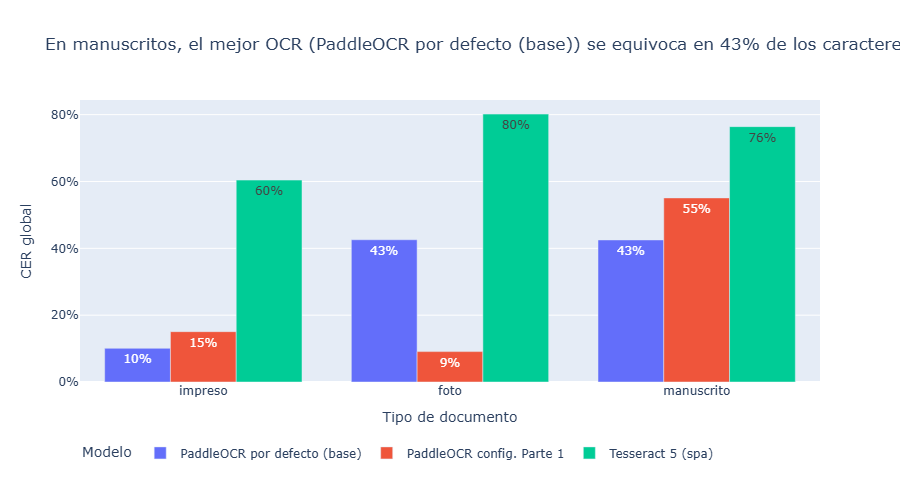

In [7]:
cer_tipo = por_doc.groupby(["tipo", "modelo"], sort=False)[["errores", "n_ref"]].sum().reset_index()
cer_tipo["CER"] = cer_tipo.errores / cer_tipo.n_ref
cer_tipo["CER_txt"] = cer_tipo.CER.map("{:.0%}".format)
if len(cer_tipo):
    peor = cer_tipo.loc[cer_tipo.CER.idxmax()]
    mejor_manus = cer_tipo[cer_tipo.tipo == "manuscrito"].sort_values("CER").iloc[0]
    impresos = cer_tipo[cer_tipo.tipo == "impreso"].CER.min()
    TITULO_4 = (f"En manuscritos, el mejor OCR ({mejor_manus.modelo}) se equivoca en {mejor_manus.CER:.0%} "
                f"de los caracteres; en impresos, el mejor llega a {impresos:.0%}")
    fig = px.bar(cer_tipo, x="tipo", y="CER", color="modelo", barmode="group", text="CER_txt",
                 title=TITULO_4, labels={"tipo": "Tipo de documento", "CER": "CER global", "modelo": "Modelo"},
                 category_orders={"tipo": ["impreso", "foto", "manuscrito"]})
    fig.update_layout(yaxis_tickformat=".0%", legend=dict(orientation="h", y=-0.2))
    fig.write_image(GRAF / "cer_por_tipo.png", width=900, height=480)
    fig.show(); display(Img(filename=str(GRAF / "cer_por_tipo.png")))

**Qué muestran los documentos.**
- **Impresos:** PaddleOCR por defecto es el mejor (CER de 10 %). Su detector más grande lee mejor la tipografía antigua de la Gazeta de 1810.
- **Manuscritos:** ningún modelo sirve para leerlos sin revisión. El mejor, PaddleOCR por defecto, se equivoca en 4 de cada 10 caracteres, y la configuración liviana de la Parte 1 llega a 55 %. Contra lo que se esperaba, lo más difícil no fue lo antiguo: la carta de 2010 con letra suelta y personal (`doc_022`) sale peor (69 %) que la cursiva caligráfica de 1912 (24 %) o la portada parroquial de 1871 (21 %). La letra cuidada y regular se lee mejor que la letra rápida, sin importar la época.
- **Fotos:** aquí la configuración por defecto sale peor (43 % frente a 9 %) por un solo archivo. En la placa de Arequipa (`doc_013`), el corrector de orientación que PaddleOCR activa por su cuenta giró la imagen y devolvió las líneas en orden invertido. Las palabras están bien leídas, pero el CER compara el texto en orden, así que cuenta casi todo como error. Por eso la Parte 1 desactivó esos módulos.
- **Tesseract:** es el peor en los tres tipos. En dos de las tres placas no devolvió nada (CER de 100 %), porque la segmentación automática de página no encuentra texto en una foto con fondo y perspectiva.

### Audio por condición de grabación
Ruido de calle o de marcha, música, varias voces que se pisan y acento andino, frente al testimonio grabado con buena calidad.

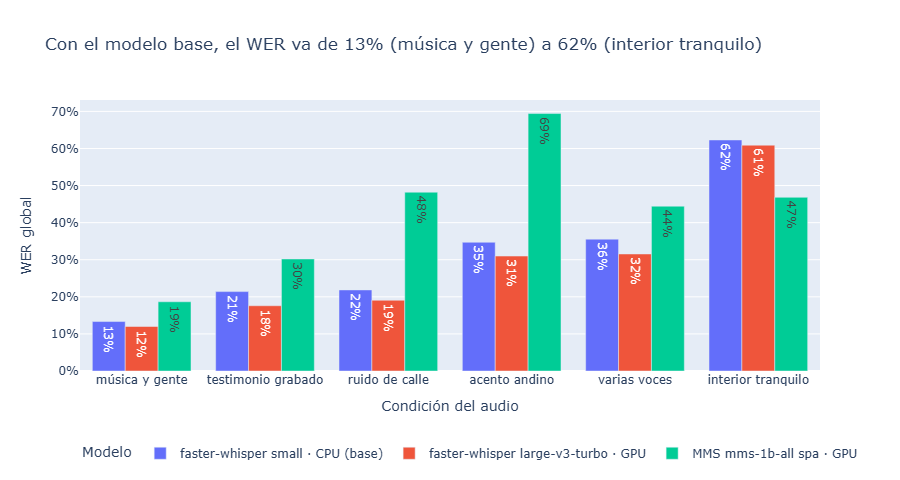

In [8]:
CONDICION = {"clip_001": "ruido de calle", "clip_015": "ruido de calle", "clip_018": "ruido de calle",
             "clip_013": "música y gente", "clip_014": "varias voces", "clip_007": "varias voces",
             "clip_012": "acento andino", "clip_010": "interior tranquilo", "clip_016": "interior tranquilo",
             "clip_023": "testimonio grabado"}
por_clip["condicion"] = por_clip.id.map(CONDICION)
wer_cond = por_clip.groupby(["condicion", "modelo"], sort=False)[["errores", "n_ref"]].sum().reset_index()
wer_cond["WER"] = wer_cond.errores / wer_cond.n_ref
wer_cond["WER_txt"] = wer_cond.WER.map("{:.0%}".format)
if len(wer_cond):
    base = wer_cond[wer_cond.modelo.str.contains("base")].sort_values("WER")
    TITULO_5 = (f"Con el modelo base, el WER va de {base.WER.min():.0%} ({base.condicion.iloc[0]}) "
                f"a {base.WER.max():.0%} ({base.condicion.iloc[-1]})")
    fig = px.bar(wer_cond, x="condicion", y="WER", color="modelo", barmode="group", text="WER_txt",
                 title=TITULO_5, labels={"condicion": "Condición del audio", "WER": "WER global", "modelo": "Modelo"},
                 category_orders={"condicion": base.condicion.tolist()})
    fig.update_layout(yaxis_tickformat=".0%", legend=dict(orientation="h", y=-0.25))
    fig.write_image(GRAF / "wer_por_condicion.png", width=900, height=480)
    fig.show(); display(Img(filename=str(GRAF / "wer_por_condicion.png")))

**Qué muestra el audio.**
- **El ruido no fue lo más difícil.** La calle con tráfico, la marcha y la fiesta con música quedaron entre los WER más bajos (13 % a 22 % con el modelo base).
- **Lo peor fue "interior tranquilo"** (alrededor de 60 % con los dos Whisper), y no por mala calidad del audio. Casi todo el error son **palabras omitidas**: en `clip_010`, Whisper se salta de una vez un bloque de 106 palabras seguidas, aunque sus marcas de tiempo cubren el clip completo. Es un fallo conocido de Whisper: en habla rápida y continua, a veces resume o salta un tramo de la ventana de 30 s.
- **MMS no tiene ese problema.** Como procesa ventanas fijas sin generar texto libre, no se salta nada y en `clip_016` gana con claridad (20 % frente a 52 %). En cambio, falla mucho más con el acento andino (69 %) y con la calle con varias voces (`clip_018`, 81 %), donde devuelve menos de la mitad de las palabras.
- **Varias voces que se pisan** suben el error de todos los modelos a un rango de 32 % a 44 %.

### Precisión frente a velocidad (ASR)

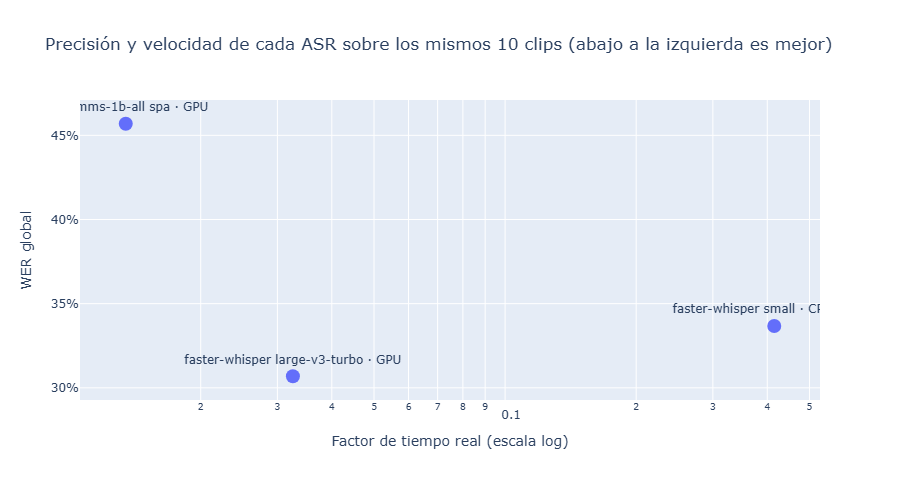

In [9]:
pv = por_clip.groupby("modelo", sort=False).agg(WER=("errores", "sum"), n=("n_ref", "sum"), RTF=("rtf", "mean")).reset_index()
pv["WER"] = pv.WER / pv.n
if len(pv):
    TITULO_6 = "Precisión y velocidad de cada ASR sobre los mismos 10 clips (abajo a la izquierda es mejor)"
    fig = px.scatter(pv, x="RTF", y="WER", text="modelo", title=TITULO_6, log_x=True,
                     labels={"RTF": "Factor de tiempo real (escala log)", "WER": "WER global"})
    fig.update_traces(textposition="top center", marker_size=14)
    fig.update_layout(yaxis_tickformat=".0%")
    fig.write_image(GRAF / "asr_precision_velocidad.png", width=900, height=480)
    fig.show(); display(Img(filename=str(GRAF / "asr_precision_velocidad.png")))

`large-v3-turbo` en GPU es a la vez el más preciso y unas 12 veces más rápido que `small` en CPU. MMS es todavía más rápido, pero comete un 50 % más de errores. La mejora de precisión de turbo sobre small es modesta (WER de 34 % a 31 %), porque los dos comparten los saltos de Whisper descritos arriba.

## 6. Extracción estructurada con LLM

Un LLM lee el texto de cada documento (OCR) y de cada clip (ASR) del corpus completo de la Parte 1 (25 + 22) y devuelve un JSON con:
- en todos: `modalidad`, `tema`, `resumen`;
- en documentos: `emisor`, `destinatario`, `fecha`, `lugar`, `monto`;
- en audios: `numero_hablantes`, `citas_clave` (frases textuales del audio).

**Reglas del prompt.** Solo datos que estén en el texto; `null` si no aparecen. Las citas deben ser textuales. No completar con conocimiento externo: por ejemplo, no poner el año de una constitución si la página no lo dice.

Se usa la salida JSON con esquema de Gemini (`response_schema`), así que el modelo no puede agregar ni quitar campos. Los textos que se envían son los **seudonimizados** de la Parte 1: ningún nombre privado sale a la API.

La respuesta de cada texto se guarda en `datos/evaluacion/llm/` y no se vuelve a pedir. La clave se lee de `.env` (fuera de Git).

In [10]:
from pydantic import BaseModel
from typing import Literal, Optional

class Extraccion(BaseModel):
    modalidad: Literal["documento", "audio"]
    tema: str
    resumen: str
    emisor: Optional[str]
    destinatario: Optional[str]
    fecha: Optional[str]
    lugar: Optional[str]
    monto: Optional[str]
    numero_hablantes: Optional[int]
    citas_clave: Optional[list[str]]

PROMPT = """Eres un archivista. Abajo va el texto de un {modalidad} peruano, obtenido automáticamente con {fuente}, así que puede tener errores de lectura.
Extrae los campos del esquema siguiendo estas reglas:
- Usa solo lo que dice el texto. Si un dato no aparece, pon null. No completes con conocimiento externo.
- tema: 2 a 6 palabras. resumen: 1 o 2 oraciones en español.
- emisor, destinatario, fecha, lugar y monto: solo en documentos y solo si aparecen escritos; copia la fecha y el monto como están.
- numero_hablantes: solo en audios; cuenta las marcas [HABLANTE_n] distintas. En documentos, null.
- citas_clave: solo en audios; 1 a 3 frases copiadas textualmente del texto. En documentos, null.
- Las marcas [PERSONA_n] son nombres ocultos: déjalas tal cual, no inventes nombres.

TEXTO:
{texto}"""

LLM_DIR = EVAL / "llm"; LLM_DIR.mkdir(parents=True, exist_ok=True)
MODELO_LLM = os.environ.get("GEMINI_MODEL", "gemini-2.5-flash")
corpus = pd.concat([
    documentos.assign(modalidad="documento", fuente="OCR (PaddleOCR)", texto=documentos.texto_ocr)[["id", "modalidad", "fuente", "texto"]],
    transcripciones.assign(modalidad="audio", fuente="reconocimiento de voz (Whisper) con marcas de hablante",
                           texto=transcripciones.texto_asr)[["id", "modalidad", "fuente", "texto"]]], ignore_index=True)

def extraer(fila, cliente):
    cache = LLM_DIR / f"{fila.id}.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))
    from google.genai import types
    r = cliente.models.generate_content(
        model=MODELO_LLM, contents=PROMPT.format(modalidad=fila.modalidad, fuente=fila.fuente, texto=fila.texto[:12000]),
        config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json", response_schema=Extraccion))
    salida = {"campos": json.loads(r.text), "modelo_llm": MODELO_LLM,
              "fecha": pd.Timestamp.now(tz="America/Lima").strftime("%Y-%m-%d")}
    cache.write_text(json.dumps(salida, ensure_ascii=False, indent=1), encoding="utf-8")
    time.sleep(1)
    return salida

pendientes = [i for i in corpus.id if not (LLM_DIR / f"{i}.json").exists()]
cliente = None
if pendientes:
    from dotenv import load_dotenv
    load_dotenv()
    if os.environ.get("GEMINI_API_KEY"):
        from google import genai
        cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
salidas = {f.id: extraer(f, cliente) for f in corpus.itertuples() if cliente or (LLM_DIR / f"{f.id}.json").exists()}
print(f"Extracciones: {len(salidas)}/{len(corpus)}", "(falta la clave GEMINI_API_KEY en .env)" if len(salidas) < len(corpus) and not cliente else "")

Extracciones: 0/47 (falta la clave GEMINI_API_KEY en .env)


In [11]:
extraccion_llm = pd.DataFrame([{"id": i, "modalidad": s["campos"]["modalidad"],
                                "campos_json": json.dumps(s["campos"], ensure_ascii=False),
                                "modelo_llm": s["modelo_llm"], "fecha": s["fecha"]} for i, s in salidas.items()],
                              columns=["id", "modalidad", "campos_json", "modelo_llm", "fecha"])
extraccion_llm.to_csv("datos/extraccion_llm.csv", index=False)
campos = pd.json_normalize([json.loads(c) for c in extraccion_llm.campos_json]).assign(id=extraccion_llm.id.values)
if len(campos):
    llenos = campos.drop(columns="id").notna().mean().rename("con dato").to_frame()
    display(llenos.style.format("{:.0%}"))
extraccion_llm.head()

,id,modalidad,campos_json,modelo_llm,fecha


## 7. Auditoría humana de 20 extracciones

Se sortean 10 documentos y 10 audios (semilla fija, 2026) y se revisan a mano contra el texto original. Los resultados quedan en `datos/auditoria_llm.csv`.

**Criterio de corrección, por campo:**
- un campo es **correcto** si su contenido está sustentado en el texto, o si es `null` y el dato de verdad no aparece;
- es **incorrecto** si inventa algo que no está, si pone `null` habiendo un dato claro, o si el resumen o el tema describen mal el contenido;
- en `citas_clave`, las frases tienen que estar en el texto (se aceptan diferencias de puntuación);
- en `numero_hablantes`, tiene que coincidir con las marcas de diarización.

Una extracción es **completamente correcta** si todos sus campos lo son.

In [12]:
AUDIT = Path("datos/auditoria_llm.csv")
CAMPOS = ["tema", "resumen", "emisor", "destinatario", "fecha", "lugar", "monto", "numero_hablantes", "citas_clave"]
rng = np.random.default_rng(2026)
sorteo = [*rng.choice(sorted(corpus.id[corpus.modalidad == "documento"]), 10, replace=False),
          *rng.choice(sorted(corpus.id[corpus.modalidad == "audio"]), 10, replace=False)]
if not AUDIT.exists() and len(salidas) == len(corpus):
    pd.DataFrame({"id": sorteo, **{c: "" for c in CAMPOS}, "errores": ""}).to_csv(AUDIT, index=False)
    print("Plantilla creada: marcar cada campo con 1 (correcto) o 0 (incorrecto) y describir los errores.")
auditoria = pd.read_csv(AUDIT, dtype=str).fillna("") if AUDIT.exists() else pd.DataFrame()
revisadas = auditoria[auditoria[CAMPOS].ne("").all(axis=1)] if len(auditoria) else auditoria
if len(revisadas):
    correctas = (revisadas[CAMPOS] == "1").all(axis=1)
    ACUERDO = f"{correctas.sum()}/{len(revisadas)}"
    print(f"Acuerdo LLM-Humano: {ACUERDO} extracciones completamente correctas ({correctas.mean():.0%})")
    display((revisadas[CAMPOS] == "1").mean().rename("campos correctos").to_frame().style.format("{:.0%}"))
    display(revisadas.loc[~correctas, ["id", "errores"]])
else:
    print("Auditoría pendiente:", sorteo)

Auditoría pendiente: [np.str_('doc_001'), np.str_('doc_r05'), np.str_('doc_004'), np.str_('doc_013'), np.str_('doc_014'), np.str_('doc_008'), np.str_('doc_002'), np.str_('doc_010'), np.str_('doc_009'), np.str_('doc_016'), np.str_('clip_013'), np.str_('clip_021'), np.str_('clip_004'), np.str_('clip_003'), np.str_('clip_022'), np.str_('clip_016'), np.str_('clip_017'), np.str_('clip_014'), np.str_('clip_023'), np.str_('clip_006')]


## 8. Comparativa final y decisión

In [13]:
tabla_final = pd.concat([tabla_ocr.rename(columns=lambda c: c.replace("CER", "error")).assign(modalidad="documentos · CER"),
                         tabla_asr.rename(columns=lambda c: c.replace("WER", "error")).assign(modalidad="audio · WER")])
tabla_final

,error promedio,error global,modalidad,RTF medio
modelo,,,,
PaddleOCR por defecto (base),0.291,0.306,documentos · CER,NaN
PaddleOCR config. Parte 1,0.282,0.369,documentos · CER,NaN
Tesseract 5 (spa),0.697,0.708,documentos · CER,NaN
faster-whisper small · CPU (base),0.335,0.337,audio · WER,0.415
faster-whisper large-v3-turbo · GPU,0.303,0.307,audio · WER,0.033
MMS mms-1b-all spa · GPU,0.447,0.457,audio · WER,0.013


**Decisión.**

| Uso | Elección | Por qué |
|---|---|---|
| Documentos impresos y fotos | PaddleOCR **sin** los módulos de orientación y enderezado (configuración de la Parte 1), con el detector `medium` si hay memoria | Los módulos automáticos desordenaron una placa entera; el detector grande lee mejor los impresos (10 % frente a 15 %). Ninguna de las dos configuraciones gana en todo, y una combinación de ambas sería el siguiente experimento. |
| Manuscritos | PaddleOCR por defecto, solo como borrador y siempre con revisión humana | CER de 42 % con el mejor modelo y de 69 % con la letra más suelta. Para un archivo real haría falta un modelo de escritura a mano (por ejemplo, TrOCR afinado o Transkribus). |
| Audio con GPU | faster-whisper `large-v3-turbo` | Menor WER (31 %) y RTF de 0,03: una hora de audio en unos 2 minutos. |
| Audio solo con CPU, como la laptop de la Parte 1 | faster-whisper `small` | Solo 3 puntos peor que turbo y con un RTF de 0,4 a 0,5, que cabe en 8 GB de RAM. |
| No elegido | Tesseract y MMS | Tesseract no lee fotos ni manuscritos. MMS es rápido, pero falla con el acento andino y con varias voces, que son justo las condiciones del corpus. |

**Límite de esta evaluación.** Son 10 documentos y 10 clips, con una sola persona transcribiendo. Las diferencias pequeñas (como 31 % frente a 34 %) dependen de pocos archivos, así que la conclusión más firme es la de los extremos: Tesseract y MMS quedan claramente atrás, y los manuscritos no se pueden leer sin una persona.

In [14]:
if len(por_clip) and len(por_doc):
    base_doc = tabla_ocr.iloc[0]["CER global"]; base_aud = tabla_asr.iloc[0]["WER global"]
    print(f"Resultados Test: WER: {base_aud:.2f} | CER: {base_doc:.2f}"
          + (f" | Acuerdo LLM-Humano: {ACUERDO}" if len(revisadas) else ""))
    print("(línea base; la tabla de arriba tiene los modelos alternativos)")

Resultados Test: WER: 0.34 | CER: 0.31
(línea base; la tabla de arriba tiene los modelos alternativos)
